# Reversible-jump inference

Infer the number, positions and rates of changes in the coal-mining disaster
record with a piecewise Poisson model. Height and position moves update a fixed
model dimension; paired birth and death moves explore different values of $k$.
The prior is a Poisson distribution with mean 3, truncated at $k\leq30$, with
Gamma segment rates and the even-order-statistic position prior.

See [methods](../docs/method.md), [data provenance](../docs/data.md),
[course framework](../docs/references.md#coursework-framework), and [RUNNING.md](../RUNNING.md).

In [1]:
from pathlib import Path
import json

import matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

ROOT = Path.cwd() if (Path.cwd() / 'pyproject.toml').is_file() else Path.cwd().parent
if not (ROOT / 'data' / 'coal_intervals_days.csv').is_file():
    raise FileNotFoundError('Run this notebook from the repository root or notebooks directory.')
DATA = ROOT / 'data' / 'coal_intervals_days.csv'
SEED = 1123
import os

from coal_changepoints.pipeline import run_analysis
from coal_changepoints.plotting import reversible_jump_figure, trace_figure

CONFIG = dict(seed=SEED, steps=20000, burn=5000, n_chains=2, m1_samples=10000)


## Run or inspect saved chains

By default this notebook runs two chains with 20,000 transitions each and
removes the first 5,000 transitions. For longer analyses, run the command-line
workflow in [RUNNING.md](../RUNNING.md), then set `S2_RESULTS_DIR` to its output
directory **before starting Jupyter**. Cached mode reads `summary.json` and
`chains_and_posteriors.npz` and does not launch new sampling.

The settings printed below come from the actual result files. They may differ
from `CONFIG` when cached mode is selected. Saved summaries alone are not a
convergence certificate.

In [2]:
cached_dir = os.environ.get('S2_RESULTS_DIR')
if cached_dir:
    results_dir = Path(cached_dir).expanduser()
    for name in ('summary.json', 'chains_and_posteriors.npz'):
        if not (results_dir / name).is_file():
            raise FileNotFoundError(f'S2_RESULTS_DIR is missing {name}.')
    summary = json.loads((results_dir / 'summary.json').read_text())
    mode = 'Saved chains (no new sampling)'
else:
    results_dir = ROOT / 'outputs' / 'notebook_rjmcmc'
    summary = run_analysis(DATA, results_dir, **CONFIG)
    mode = 'Fresh sampling'

with np.load(results_dir / 'chains_and_posteriors.npz', allow_pickle=False) as saved:
    arrays = {name: saved[name] for name in saved.files}

settings = {name: summary[name] for name in (
    'seed', 'n_events', 'duration_days', 'n_chains', 'steps_per_chain',
    'burn_transitions', 'retained_per_chain', 'rate_stride', 'rate_summary_draws',
)}
print(mode)
print(json.dumps(settings, indent=2))


Saved chains (no new sampling)
{
  "seed": 1123,
  "n_events": 191,
  "duration_days": 40549.0,
  "n_chains": 4,
  "steps_per_chain": 100000,
  "burn_transitions": 10000,
  "retained_per_chain": 90000,
  "rate_stride": 20,
  "rate_summary_draws": 18000
}


## Posterior model probabilities and event rate

Model frequencies use every retained draw. The rate curve uses the recorded
`rate_stride` to reduce plotting cost. The shaded bands are pointwise central
credible intervals, not simultaneous bands for an entire rate function.

A model receiving no visits is not assigned an exact zero posterior probability
by theory; it has zero frequency in these finite chains.

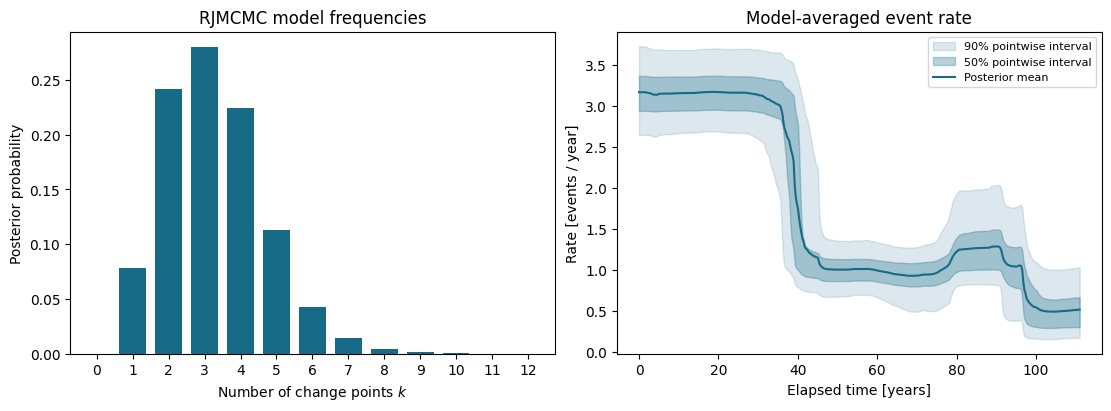

k   Posterior frequency
 1  0.077800
 2  0.241189
 3  0.279975
 4  0.224581
 5  0.113117
 6  0.042844
 7  0.014144
 8  0.004425
 9  0.001425
10  0.000425
11  0.000072
12  0.000003


In [3]:
k_values = arrays['k_values']
probabilities = arrays['k_probabilities']
rate = {name: arrays[f'rate_{name}'] for name in ('time_days', 'mean', 'p5', 'p25', 'p75', 'p95')}
fig = reversible_jump_figure(k_values, probabilities, rate)
display(fig)
plt.close(fig)

print('k   Posterior frequency')
for k, probability in zip(k_values, probabilities):
    if probability > 0:
        print(f'{k:2d}  {probability:.6f}')


## Mixing and scalar diagnostics

Inspect both the discrete model index and the integrated rate, which is the
expected event count under a sampled intensity. The grey region marks burn-in;
the plotting function subsamples long traces for display only. Classical split
$\widehat R$ and autocorrelation-based effective sample sizes are reported for
these scalar summaries, not for the complete variable-dimensional state.

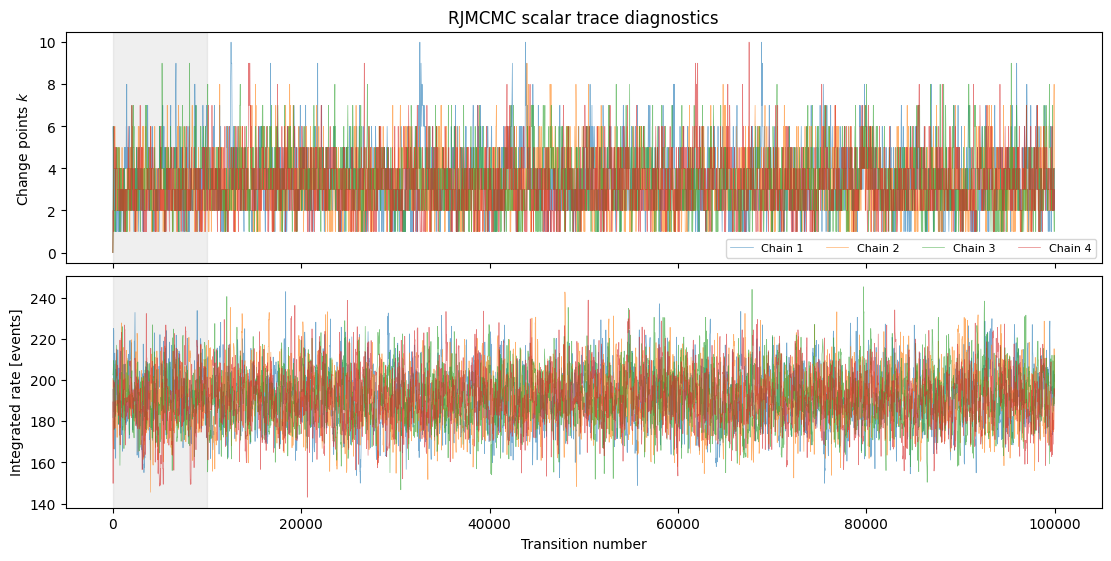

{
  "k_split_rhat": 1.0015064861938516,
  "integrated_rate_split_rhat": 1.0003249863416932,
  "k_ess_per_chain": [
    528.4244394258674,
    641.7719890667531,
    711.377389576241,
    728.0323696440342
  ],
  "integrated_rate_ess_per_chain": [
    962.9969388286021,
    1156.5700828836914,
    897.2401382326055,
    807.3084467234138
  ]
}


In [4]:
fig = trace_figure(
    arrays['k_chains'], arrays['integrated_rate_chains'], summary['burn_transitions'],
)
display(fig)
plt.close(fig)
print(json.dumps(summary['diagnostics'], indent=2))


## Proposal activity

Acceptance fractions below include all attempted transitions, including
burn-in. Compare chains and move types alongside the traces; a high acceptance
fraction by itself does not imply effective exploration.

In [5]:
print('Chain  Move       Attempts  Accepted  Acceptance')
for chain_index, move_statistics in enumerate(summary['move_statistics'], start=1):
    for move, values in move_statistics.items():
        print(f"{chain_index:5d}  {move:9s}  {values['attempted']:8d}  {values['accepted']:8d}  {values['acceptance']:10.3f}")


Chain  Move       Attempts  Accepted  Acceptance
    1  height         8628      8628       1.000
    1  position       8773      1924       0.219
    1  birth         37980      8884       0.234
    1  death         44619      8880       0.199
    2  height         8557      8557       1.000
    2  position       8500      1824       0.215
    2  birth         38694      8932       0.231
    2  death         44249      8928       0.202
    3  height         8389      8389       1.000
    3  position       8480      1842       0.217
    3  birth         38575      9106       0.236
    3  death         44556      9102       0.204
    4  height         8558      8558       1.000
    4  position       8397      1725       0.205
    4  birth         38916      9053       0.233
    4  death         44129      9050       0.205


## Limits of the analysis

The modal value of $k$ summarises the most frequently visited model, while the
rate curve averages over model uncertainty. Short chains can miss rare model
transitions. Agreement of these scalar diagnostics does not exclude poor
mixing in change-point locations or separate posterior modes.

The historical events are treated as a Poisson process on the stated
observation interval. No mine exposure, reporting covariates or causal policy
model is included. Model probabilities depend on the rate, position and
model-size priors. Use additional independent runs and prior sensitivity
checks before drawing conclusions beyond this model and dataset.